In [1]:
import os
import glob
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# 1. Locate and Load the Dataset
# -------------------------------------------------------------
# Find the exact CSV file mounted in /kaggle/input
file_matches = glob.glob('/kaggle/input/**/*.csv', recursive=True)

if not file_matches:
    raise FileNotFoundError("No CSV file found in /kaggle/input. Verify the dataset is attached.")

raw_path = file_matches[0]
print(f"Loading raw data from: {raw_path}")

df_raw = pd.read_csv(raw_path)
print(f"Raw shape: {df_raw.shape[0]:,} rows | {df_raw.shape[1]} columns")

# Standardize column headers
df_raw.columns = df_raw.columns.str.strip().str.lower().str.replace(' ', '_')

# -------------------------------------------------------------
# 2. Filter to Virginia & Active 'for_sale' Listings
# -------------------------------------------------------------
# Standardize state text and slice
df_va = df_raw[df_raw['state'].astype(str).str.strip().str.title() == 'Virginia'].copy()

# Keep active residential sales (filters out pending land/construction tracts)
if 'status' in df_va.columns:
    df_va = df_va[df_va['status'].astype(str).str.lower().str.contains('for_sale', na=False)]

print(f"Virginia 'for_sale' listings: {len(df_va):,} rows")

# -------------------------------------------------------------
# 3. Clean Missing Core Values & Standardize Formats
# -------------------------------------------------------------
# Drop listings missing baseline price, size, or location values
df_va = df_va.dropna(subset=['price', 'house_size', 'zip_code', 'city'])

# Format zip codes: ensure 5-digit string format (e.g., handles 23602.0 -> "23602")
df_va['zip_code'] = (
    df_va['zip_code']
    .astype(float)
    .astype(int)
    .astype(str)
    .str.zfill(5)
)

# Standardize city names
df_va['city'] = df_va['city'].astype(str).str.strip().str.title()

# -------------------------------------------------------------
# 4. Deduplicate Across Scrapes & Filter Realistic Bounds
# -------------------------------------------------------------
# Deduplicate properties repeated across scrape runs
dedup_cols = ['street', 'city', 'zip_code', 'price', 'house_size', 'bed', 'bath']
existing_dedup = [c for c in dedup_cols if c in df_va.columns]
df_va = df_va.drop_duplicates(subset=existing_dedup, keep='last')

# Filter residential bounds (removes commercial tracts, $0 placeholders, and entry typos)
cleaned_df = df_va[
    (df_va['price'] >= 50_000) & (df_va['price'] <= 5_000_000) &
    (df_va['house_size'] >= 400) & (df_va['house_size'] <= 15_000) &
    (df_va['bed'] >= 1) & (df_va['bed'] <= 10) &
    (df_va['bath'] >= 1) & (df_va['bath'] <= 10)
].copy()

# -------------------------------------------------------------
# 5. Feature Engineering: Price per Sq Ft & Ratios
# -------------------------------------------------------------
cleaned_df['price_per_sqft'] = (cleaned_df['price'] / cleaned_df['house_size']).round(2)
cleaned_df['bed_bath_ratio'] = (cleaned_df['bed'] / cleaned_df['bath']).round(2)

# Impute missing lot acreage using the median lot size for that zip code
if 'acre_lot' in cleaned_df.columns:
    zip_median_lot = cleaned_df.groupby('zip_code')['acre_lot'].transform('median')
    cleaned_df['acre_lot'] = cleaned_df['acre_lot'].fillna(zip_median_lot).fillna(0.25)

# Drop redundant or extraneous columns
drop_cols = ['brokered_by', 'state', 'prev_sold_date']
cleaned_df = cleaned_df.drop(columns=[c for c in drop_cols if c in cleaned_df.columns])

print("\n--- Cleaning Complete ---")
print(f"Final Cleaned Virginia Dataset: {cleaned_df.shape[0]:,} rows | {cleaned_df.shape[1]} columns")
print(cleaned_df[['city', 'zip_code', 'price', 'house_size', 'price_per_sqft']].head())

# -------------------------------------------------------------
# 6. Save Clean Slice to Kaggle Working Directory
# -------------------------------------------------------------
output_path = "/kaggle/working/cleaned_va_real_estate.csv"
cleaned_df.to_csv(output_path, index=False)
print(f"\nSaved successfully to: {output_path}")

Loading raw data from: /kaggle/input/datasets/ahmedshahriarsakib/usa-real-estate-dataset/realtor-data.zip.csv
Raw shape: 2,226,382 rows | 12 columns
Virginia 'for_sale' listings: 35,572 rows

--- Cleaning Complete ---
Final Cleaned Virginia Dataset: 23,437 rows | 11 columns
                  city zip_code     price  house_size  price_per_sqft
183565    Lovettsville    20180  850000.0      4620.0          183.98
185183  Cross Junction    22625  399000.0      2000.0          199.50
185186      Winchester    22601  345000.0      1550.0          222.58
185187   Stephens City    22655  299900.0      1254.0          239.15
185194      Winchester    22602  385000.0      2033.0          189.38

Saved successfully to: /kaggle/working/cleaned_va_real_estate.csv


In [2]:
df_va.head()

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
183565,22611.0,for_sale,850000.0,4.0,4.0,10.10,1205251.0,Lovettsville,Virginia,20180,4620.0,2006-12-01
185183,16806.0,for_sale,399000.0,4.0,3.0,0.34,625163.0,Cross Junction,Virginia,22625,2000.0,NaN
185186,91257.0,for_sale,345000.0,2.0,2.0,0.09,555459.0,Winchester,Virginia,22601,1550.0,2014-09-30
185187,30228.0,for_sale,299900.0,3.0,2.0,0.27,68350.0,Stephens City,Virginia,22655,1254.0,2014-12-11
185194,22611.0,for_sale,385000.0,3.0,4.0,0.00,67824.0,Winchester,Virginia,22602,2033.0,2021-07-23


In [3]:
# Aggregate by city using your in-memory cleaned_df
city_summary = cleaned_df.groupby('city').agg(
    listing_count=('price', 'count'),
    median_price=('price', 'median'),
    median_sqft=('house_size', 'median'),
    median_price_per_sqft=('price_per_sqft', 'median')
).reset_index()

# Filter for active submarkets (>= 50 listings) to drop noisy small towns
top_markets = (
    city_summary[city_summary['listing_count'] >= 50]
    .sort_values(by='listing_count', ascending=False)
    .head(15)
    .copy()
)

# Format currency and square footage for clean display
top_markets['median_price'] = top_markets['median_price'].map('${:,.0f}'.format)
top_markets['median_sqft'] = top_markets['median_sqft'].map('{:,.0f} sqft'.format)
top_markets['median_price_per_sqft'] = top_markets['median_price_per_sqft'].map('${:.2f}/sqft'.format)

print("=== Top 15 Virginia Submarkets by Volume ===")
print(top_markets.to_string(index=False))

=== Top 15 Virginia Submarkets by Volume ===
           city  listing_count median_price median_sqft median_price_per_sqft
       Richmond           1501     $335,000  1,729 sqft          $197.58/sqft
     Alexandria            901     $619,900  1,479 sqft          $363.51/sqft
      Arlington            638     $687,250  1,326 sqft          $461.25/sqft
 Fredericksburg            617     $485,000  2,462 sqft          $194.16/sqft
Charlottesville            560     $493,808  2,203 sqft          $225.29/sqft
        Roanoke            475     $265,500  1,800 sqft          $144.42/sqft
     Woodbridge            442     $450,000  1,974 sqft          $220.20/sqft
     Midlothian            432     $425,000  2,274 sqft          $187.71/sqft
 Virginia Beach            422     $359,950  1,755 sqft          $200.71/sqft
   Williamsburg            375     $445,000  2,388 sqft          $197.96/sqft
   Chesterfield            342     $416,950  2,385 sqft          $175.25/sqft
 Mechanicsville    

In [4]:
# -------------------------------------------------------------
# Day 2: Geocode Virginia Zip Codes to Lat / Lon Coordinates
# -------------------------------------------------------------
!pip install -q pgeocode

import pgeocode

# Initialize US geocoder
nomi = pgeocode.Nominatim('us')

# Extract unique zip codes to avoid redundant lookups
unique_zips = cleaned_df['zip_code'].dropna().unique().tolist()
geo_lookup = nomi.query_postal_code(unique_zips)[['postal_code', 'latitude', 'longitude']]

# Standardize key format and merge back onto cleaned_df
geo_lookup['postal_code'] = geo_lookup['postal_code'].astype(str).str.zfill(5)
cleaned_df = cleaned_df.merge(
    geo_lookup, 
    left_on='zip_code', 
    right_on='postal_code', 
    how='left'
).drop(columns=['postal_code'])

# Drop listings with unmapped/P.O. Box zip codes
cleaned_df = cleaned_df.dropna(subset=['latitude', 'longitude'])

print(f"Geocoding complete! {len(cleaned_df):,} properties have valid (lat, lon) coordinates.")
print(cleaned_df[['city', 'zip_code', 'latitude', 'longitude', 'price_per_sqft']].head(3))

Geocoding complete! 23,435 properties have valid (lat, lon) coordinates.
             city zip_code  latitude  longitude  price_per_sqft
0    Lovettsville    20180   39.2204   -77.6596          183.98
1  Cross Junction    22625   39.3744   -78.3081          199.50
2      Winchester    22601   39.1858   -78.1827          222.58


In [5]:
# -------------------------------------------------------------
# Day 3: Submarket Benchmarking & Spatial Feature Engineering
# -------------------------------------------------------------
import numpy as np

# 1. Zip-Code Level Submarket Baselines
zip_stats = cleaned_df.groupby('zip_code').agg(
    zip_median_price_sqft=('price_per_sqft', 'median'),
    zip_listing_count=('price', 'count')
).reset_index()

# 2. City Level Baselines (Fallback for zip codes with very few listings)
city_stats = cleaned_df.groupby('city').agg(
    city_median_price_sqft=('price_per_sqft', 'median')
).reset_index()

# 3. Merge baselines back into main DataFrame
cleaned_df = cleaned_df.merge(zip_stats, on='zip_code', how='left')
cleaned_df = cleaned_df.merge(city_stats, on='city', how='left')

# For zip codes with < 5 listings, blend with city median to avoid noisy small-sample bias
cleaned_df['submarket_median_price_sqft'] = np.where(
    cleaned_df['zip_listing_count'] >= 5,
    cleaned_df['zip_median_price_sqft'],
    cleaned_df['city_median_price_sqft']
)

# 4. Feature Engineering: Density and Space Allocation
cleaned_df['bath_per_bed'] = (cleaned_df['bath'] / cleaned_df['bed']).round(2)
cleaned_df['sqft_per_bed'] = (cleaned_df['house_size'] / cleaned_df['bed']).round(1)

# Log-transform target price and lot size to normalize positive skew for tree modeling
cleaned_df['log_price'] = np.log1p(cleaned_df['price'])
cleaned_df['log_acre_lot'] = np.log1p(cleaned_df['acre_lot'])

print("--- Day 3 Submarket Feature Matrix Ready ---")
print(cleaned_df[[
    'city', 'zip_code', 'price', 'house_size', 
    'price_per_sqft', 'submarket_median_price_sqft', 
    'latitude', 'longitude'
]].head(5))

--- Day 3 Submarket Feature Matrix Ready ---
             city zip_code     price  house_size  price_per_sqft  \
0    Lovettsville    20180  850000.0      4620.0          183.98   
1  Cross Junction    22625  399000.0      2000.0          199.50   
2      Winchester    22601  345000.0      1550.0          222.58   
3   Stephens City    22655  299900.0      1254.0          239.15   
4      Winchester    22602  385000.0      2033.0          189.38   

   submarket_median_price_sqft  latitude  longitude  
0                       205.61   39.2204   -77.6596  
1                       188.24   39.3744   -78.3081  
2                       190.33   39.1858   -78.1827  
3                       190.10   39.0834   -78.1907  
4                       197.30   39.1501   -78.2690  


In [6]:
# -------------------------------------------------------------
# Day 4: Predictive Model Training (LightGBM Regressor)
# -------------------------------------------------------------
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error

# 1. Define Features and Target
# Using log_price stabilizes variance and limits the distorting pull of multi-million dollar listings
feature_cols = [
    'house_size', 'bed', 'bath', 'bath_per_bed', 'sqft_per_bed',
    'log_acre_lot', 'latitude', 'longitude', 'submarket_median_price_sqft'
]
target_col = 'log_price'

X = cleaned_df[feature_cols]
y = cleaned_df[target_col]

# 2. 80/20 Train-Test Split with a fixed seed for reproducible results
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 3. Initialize and Train LightGBM Regressor
lgb_model = lgb.LGBMRegressor(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
)

# 4. Invert Log Predictions Back to Real-Dollar Scale
y_pred_log = lgb_model.predict(X_test)
y_pred_dollars = np.expm1(y_pred_log)
y_test_dollars = np.expm1(y_test)

# 5. Model Evaluation Metrics
r2 = r2_score(y_test, y_pred_log)
rmse_dollars = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars))
mape = mean_absolute_percentage_error(y_test_dollars, y_pred_dollars)

print("=== Day 4 LightGBM Model Performance ===")
print(f"R² Score (Variance Explained):   {r2:.4f}")
print(f"Dollar RMSE:                     ${rmse_dollars:,.2f}")
print(f"MAPE (Mean Absolute % Error):     {mape * 100:.2f}%")

# 6. Feature Importance Breakdown
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance (Splits)': lgb_model.feature_importances_
}).sort_values(by='Importance (Splits)', ascending=False)

print("\n--- Top Predictive Features ---")
print(importance_df.to_string(index=False))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004999 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1563
[LightGBM] [Info] Number of data points in the train set: 18748, number of used features: 9
[LightGBM] [Info] Start training from score 12.944218
=== Day 4 LightGBM Model Performance ===
R² Score (Variance Explained):   0.8502
Dollar RMSE:                     $198,736.96
MAPE (Mean Absolute % Error):     19.48%

--- Top Predictive Features ---
                    Feature  Importance (Splits)
               log_acre_lot                 1931
submarket_median_price_sqft                 1899
                 house_size                 1773
                  longitude                 1761
               sqft_per_bed                 1680
                   latitude                 1670
               bath_per_bed                  551
  

In [7]:
# -------------------------------------------------------------
# Day 5: Score Dataset & Categorize Residual Valuation Spreads
# -------------------------------------------------------------
import numpy as np
import pandas as pd

# 1. Generate Model Predictions Across the Entire Virginia Dataset
log_preds = lgb_model.predict(cleaned_df[feature_cols])
cleaned_df['modeled_fair_value'] = np.expm1(log_preds).round(0)

# 2. Compute Valuation Metrics
# Positive dollar residual = Property listed below model expectation (potential deal)
# Negative dollar residual = Property listed above model expectation (premium/overpriced)
cleaned_df['valuation_residual_dollars'] = (
    cleaned_df['modeled_fair_value'] - cleaned_df['price']
).round(0)

cleaned_df['discount_spread_pct'] = (
    (cleaned_df['valuation_residual_dollars'] / cleaned_df['modeled_fair_value']) * 100
).round(2)

# 3. Categorize into Actionable Investment Tiers
conditions = [
    (cleaned_df['discount_spread_pct'] >= 15.0),
    (cleaned_df['discount_spread_pct'] <= -15.0)
]
choices = ['Value / Discount', 'Premium / Overpriced']
cleaned_df['market_position'] = np.select(conditions, choices, default='Fair Market')

# 4. Distribution Breakdown
print("=== Day 5 Valuation Spread Breakdown ===")
tier_counts = cleaned_df['market_position'].value_counts()
tier_percents = (cleaned_df['market_position'].value_counts(normalize=True) * 100).round(1)
tier_summary = pd.DataFrame({'Count': tier_counts, 'Share': tier_percents.astype(str) + '%'})
print(tier_summary.to_string())

# 5. Top 5 Value-Add / Discount Opportunities
print("\n--- Sample Top 'Value / Discount' Listings ---")
cols_to_view = [
    'city', 'zip_code', 'bed', 'bath', 'house_size', 
    'price', 'modeled_fair_value', 'discount_spread_pct'
]
top_discounts = (
    cleaned_df[cleaned_df['market_position'] == 'Value / Discount']
    .sort_values(by='discount_spread_pct', ascending=False)
    .head(5)
    .copy()
)

top_discounts['price'] = top_discounts['price'].map('${:,.0f}'.format)
top_discounts['modeled_fair_value'] = top_discounts['modeled_fair_value'].map('${:,.0f}'.format)
top_discounts['discount_spread_pct'] = top_discounts['discount_spread_pct'].map('{:+.1f}%'.format)

print(top_discounts.to_string(index=False))

=== Day 5 Valuation Spread Breakdown ===
                      Count  Share
market_position                   
Fair Market           14156  60.4%
Premium / Overpriced   5063  21.6%
Value / Discount       4216  18.0%

--- Sample Top 'Value / Discount' Listings ---
  status    price  bed  bath  acre_lot    street       city zip_code  house_size  price_per_sqft  bed_bath_ratio  latitude  longitude  zip_median_price_sqft  zip_listing_count  city_median_price_sqft  submarket_median_price_sqft  bath_per_bed  sqft_per_bed  log_price  log_acre_lot modeled_fair_value  valuation_residual_dollars discount_spread_pct  market_position
for_sale  $87,900  3.0   1.0    188.00  876045.0 Dunnsville    22454      1000.0           87.90            3.00   37.8527   -76.8475                189.290                  7                 189.290                      189.290          0.33         333.3  11.383966      5.241747         $1,039,708                    951808.0              +91.5% Value / Discount
for_

In [10]:
# -------------------------------------------------------------
# Day 6 (Fixed): Clean, Keyless Esri Basemap (No 403, No Watermarks)
# -------------------------------------------------------------
import folium
from folium.plugins import FastMarkerCluster

# 1. Virginia Centroid
va_center_lat, va_center_lon = 37.5407, -77.4360

# 2. Use Esri World Canvas (Clean, public, keyless, zero localhost/file:// blocks)
esri_tile_url = 'https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}'
esri_attribution = 'Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ'

m = folium.Map(
    location=[va_center_lat, va_center_lon],
    zoom_start=8,
    tiles=esri_tile_url,
    attr=esri_attribution,
    prefer_canvas=True
)

# 3. Base Clustered Layer: All 23k Properties
cluster_data = cleaned_df[['latitude', 'longitude']].values.tolist()
FastMarkerCluster(data=cluster_data, name="All Virginia Inventory (Density)").add_to(m)

# 4. Targeted Investment Layer: Top Value Opportunities (>= 25% Discount)
value_deals = cleaned_df[cleaned_df['discount_spread_pct'] >= 25.0].copy()
value_group = folium.FeatureGroup(name="Top Value Opportunities (>= 25% Discount)")

for _, row in value_deals.head(500).iterrows():
    popup_html = f"""
    <div style="font-family: Arial, sans-serif; width: 220px; font-size: 13px; line-height: 1.4;">
        <h4 style="margin: 0 0 5px 0; color: #1B5E20;">{row['city']}, VA {row['zip_code']}</h4>
        <b>List Price:</b> ${row['price']:,.0f}<br>
        <b>Model Fair Value:</b> ${row['modeled_fair_value']:,.0f}<br>
        <b>Discount Spread:</b> <span style="color: #1B5E20; font-weight: bold;">{row['discount_spread_pct']:+.1f}%</span><br>
        <hr style="margin: 6px 0; border: 0; border-top: 1px solid #ccc;">
        <b>Specs:</b> {row['bed']:.0f}b / {row['bath']:.1f}ba | {row['house_size']:,.0f} sqft<br>
        <b>Price/SqFt:</b> ${row['price_per_sqft']:.2f} <span style="color: #666;">(Submarket: ${row['submarket_median_price_sqft']:.2f})</span>
    </div>
    """
    
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=5,
        color="#0D5302",
        fill=True,
        fill_color="#2E7D32",
        fill_opacity=0.85,
        weight=1,
        tooltip=f"{row['city']} | List: ${row['price']:,.0f} | Spread: {row['discount_spread_pct']:+.1f}%",
        popup=folium.Popup(popup_html, max_width=250)
    ).add_to(value_group)

value_group.add_to(m)

# 5. Layer Controls
folium.LayerControl(collapsed=False).add_to(m)

# 6. Save Clean Map
map_output_path = "/kaggle/working/virginia_real_estate_valuation_map.html"
m.save(map_output_path)
print(f"Clean, watermark-free map saved to: {map_output_path}")

Clean, watermark-free map saved to: /kaggle/working/virginia_real_estate_valuation_map.html


<>:63: SyntaxWarning: invalid escape sequence '\$'
<>:67: SyntaxWarning: invalid escape sequence '\$'
<>:68: SyntaxWarning: invalid escape sequence '\$'
<>:90: SyntaxWarning: invalid escape sequence '\$'
<>:91: SyntaxWarning: invalid escape sequence '\$'
<>:92: SyntaxWarning: invalid escape sequence '\$'
<>:63: SyntaxWarning: invalid escape sequence '\$'
<>:67: SyntaxWarning: invalid escape sequence '\$'
<>:68: SyntaxWarning: invalid escape sequence '\$'
<>:90: SyntaxWarning: invalid escape sequence '\$'
<>:91: SyntaxWarning: invalid escape sequence '\$'
<>:92: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_50/1359686384.py:63: SyntaxWarning: invalid escape sequence '\$'
  f"\${p.get_width():.0f}",
/tmp/ipykernel_50/1359686384.py:67: SyntaxWarning: invalid escape sequence '\$'
  ax2.set_title("Top 10 High-Volume Submarkets\nby Median \$/Sq Ft", fontsize=12, fontweight='bold', pad=10)
/tmp/ipykernel_50/1359686384.py:68: SyntaxWarning: invalid escape sequence '\$'
  ax2.set_x

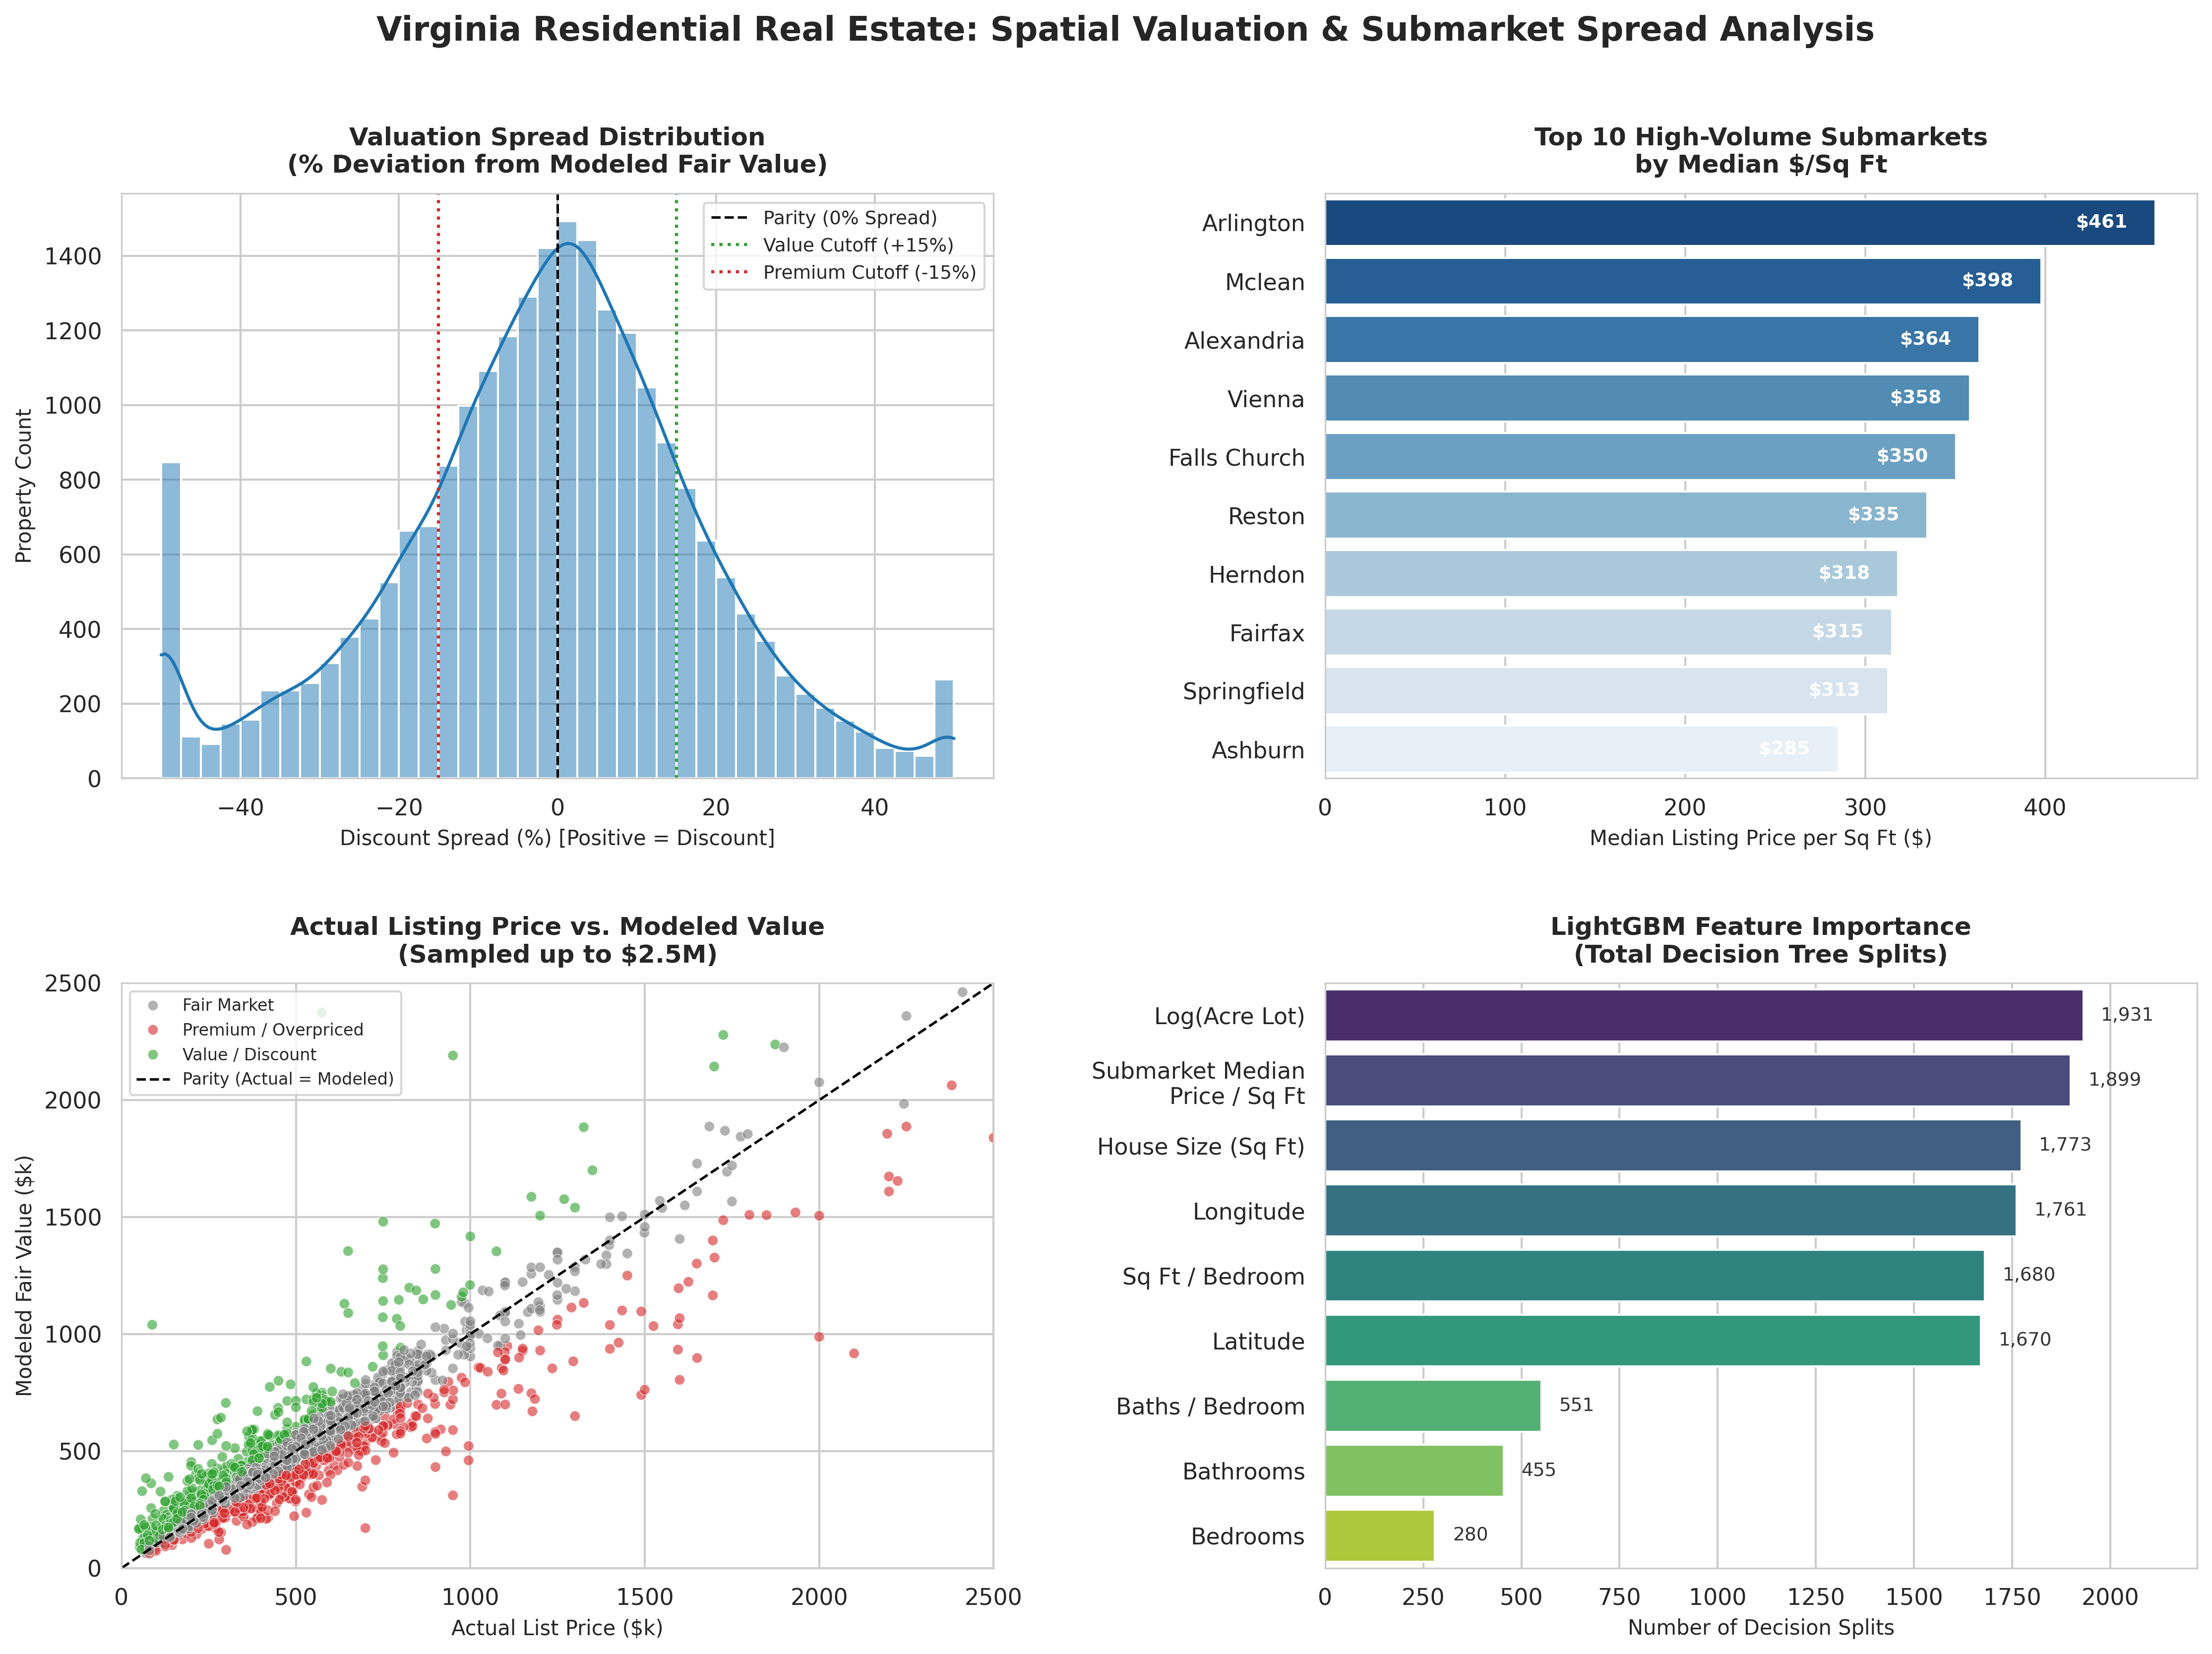

Unified graphic re-exported cleanly to: /kaggle/working/virginia_real_estate_insights.png


In [12]:
# -------------------------------------------------------------
# Day 7 (Refined): Clean Formatting, Text Wrapping & Spacing
# -------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import textwrap

# Set theme styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8
})

# Expand width and horizontal spacing to prevent label collision
fig, axes = plt.subplots(2, 2, figsize=(18, 12), dpi=300)
plt.subplots_adjust(hspace=0.35, wspace=0.38)

# ---------------------------------------------------------
# Plot 1: Model Valuation Residual Distribution
# ---------------------------------------------------------
ax1 = axes[0, 0]
sns.histplot(
    cleaned_df['discount_spread_pct'].clip(-50, 50),
    bins=40,
    kde=True,
    color="#1f77b4",
    edgecolor="white",
    ax=ax1
)
ax1.axvline(0, color="black", linestyle="--", linewidth=1.2, label="Parity (0% Spread)")
ax1.axvline(15, color="#2ca02c", linestyle=":", linewidth=1.5, label="Value Cutoff (+15%)")
ax1.axvline(-15, color="#d62728", linestyle=":", linewidth=1.5, label="Premium Cutoff (-15%)")
ax1.set_title("Valuation Spread Distribution\n(% Deviation from Modeled Fair Value)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Discount Spread (%) [Positive = Discount]", fontsize=10)
ax1.set_ylabel("Property Count", fontsize=10)
ax1.legend(loc="upper right", frameon=True, fontsize=9)

# ---------------------------------------------------------
# Plot 2: Top Submarkets Median Price / Sq Ft
# ---------------------------------------------------------
ax2 = axes[0, 1]
submarket_viz = (
    cleaned_df.groupby('city')
    .filter(lambda x: len(x) >= 100)
    .groupby('city')['price_per_sqft']
    .median()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
sns.barplot(
    data=submarket_viz,
    x='price_per_sqft',
    y='city',
    palette="Blues_r",
    ax=ax2
)
for p in ax2.patches:
    ax2.annotate(
        f"\${p.get_width():.0f}",
        (p.get_width() - 30, p.get_y() + p.get_height() / 2.),
        ha='center', va='center', color='white', fontweight='bold', fontsize=9
    )
ax2.set_title("Top 10 High-Volume Submarkets\nby Median \$/Sq Ft", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Median Listing Price per Sq Ft (\$)", fontsize=10)
ax2.set_ylabel("", fontsize=10)

# ---------------------------------------------------------
# Plot 3: Actual List Price vs. Modeled Fair Value
# ---------------------------------------------------------
ax3 = axes[1, 0]
sample_df = cleaned_df.sample(n=min(2000, len(cleaned_df)), random_state=42)
sns.scatterplot(
    data=sample_df,
    x=sample_df['price'] / 1000,
    y=sample_df['modeled_fair_value'] / 1000,
    hue='market_position',
    palette={'Fair Market': '#7f7f7f', 'Value / Discount': '#2ca02c', 'Premium / Overpriced': '#d62728'},
    alpha=0.6,
    s=25,
    ax=ax3
)
max_val = 2500
ax3.plot([0, max_val], [0, max_val], color='black', linestyle='--', linewidth=1.2, label='Parity (Actual = Modeled)')
ax3.set_xlim(0, max_val)
ax3.set_ylim(0, max_val)
ax3.set_title("Actual Listing Price vs. Modeled Value\n(Sampled up to \$2.5M)", fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel("Actual List Price (\$k)", fontsize=10)
ax3.set_ylabel("Modeled Fair Value (\$k)", fontsize=10)
ax3.legend(loc="upper left", frameon=True, fontsize=8)

# ---------------------------------------------------------
# Plot 4: LightGBM Feature Importance (Wrapped Labels)
# ---------------------------------------------------------
ax4 = axes[1, 1]

# Format feature labels with clean text wrapping
plot_importance = importance_df.copy()
label_map = {
    'submarket_median_price_sqft': 'Submarket Median\nPrice / Sq Ft',
    'log_acre_lot': 'Log(Acre Lot)',
    'house_size': 'House Size (Sq Ft)',
    'sqft_per_bed': 'Sq Ft / Bedroom',
    'longitude': 'Longitude',
    'latitude': 'Latitude',
    'bath_per_bed': 'Baths / Bedroom',
    'bath': 'Bathrooms',
    'bed': 'Bedrooms'
}
plot_importance['Feature_Clean'] = plot_importance['Feature'].map(label_map).fillna(plot_importance['Feature'])

sns.barplot(
    data=plot_importance,
    x='Importance (Splits)',
    y='Feature_Clean',
    palette="viridis",
    ax=ax4
)
for p in ax4.patches:
    ax4.annotate(
        f"{int(p.get_width()):,}",
        (p.get_width() + 45, p.get_y() + p.get_height() / 2.),
        ha='left', va='center', color='#333333', fontsize=9
    )
ax4.set_xlim(0, plot_importance['Importance (Splits)'].max() * 1.15)
ax4.set_title("LightGBM Feature Importance\n(Total Decision Tree Splits)", fontsize=12, fontweight='bold', pad=10)
ax4.set_xlabel("Number of Decision Splits", fontsize=10)
ax4.set_ylabel("", fontsize=10)

# Main Title
fig.suptitle(
    "Virginia Residential Real Estate: Spatial Valuation & Submarket Spread Analysis",
    fontsize=16,
    fontweight='bold',
    y=0.98
)

# Export complete unified graphic
plt.savefig("/kaggle/working/virginia_real_estate_insights.png", bbox_inches='tight')
plt.show()

print("Unified graphic re-exported cleanly to: /kaggle/working/virginia_real_estate_insights.png")